# Image Fourier 2


## Imports


In [1]:
import   numpy  as  np
import   matplotlib.pyplot     as  plt
from  skimage.draw     import  disk
from  skimage.feature     import   match_template
from skimage import io, data, restoration
from skimage.util import img_as_ubyte, img_as_float
from  scipy.signal     import  convolve2d
from  scipy.fft    import   fft2, fftshift, ifft2


## 1 High pass filtering

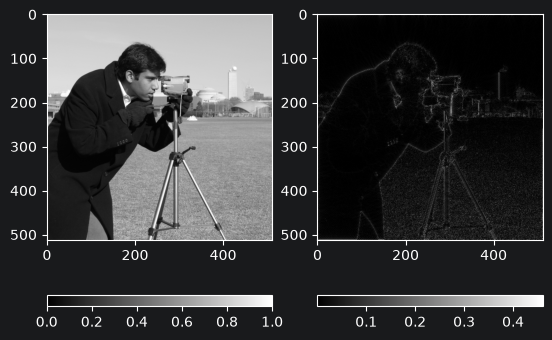

In [10]:
im  = img_as_float(data.camera())
r  = 100
imw  =  np.ones_like(im)
cx, cy   = np.round(np.array(im.shape)/2)
rr, cc   = disk((cx, cy), r, shape=im.shape)
imw[rr, cc]    =  0
imfft   = fftshift(fft2(im))
imm  =  np.log(np.abs(imfft))
imfft[imw==0]     = 0
imf  =  np.abs(ifft2(imfft))
fig  =  plt.figure()
ax  = fig.add_subplot(1,      2,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      2,  2)
p  = plt.imshow(imf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## 2 Butterworth High Pass Filter

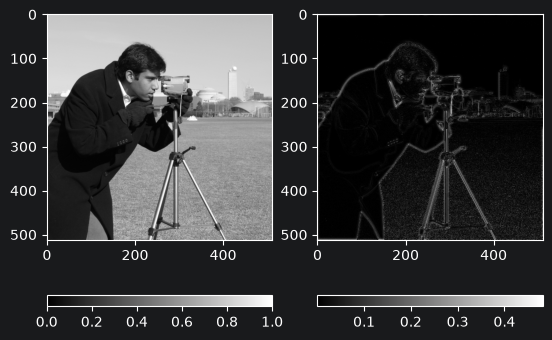

In [9]:
im  = img_as_float(data.camera())
xs, ys   = np.array(im.shape)
xl  = np.arange(xs)
yl  = np.arange(ys)
x, y  =  np.meshgrid(xl, yl, indexing='ij')
x =  (x-xs//2)/xs
y =  (y-ys//2)/ys
n =  1
K =  0.1
imw = (x**2+y**2)**n / ((x**2+y**2)**n + K**(2*n))
imfft  =  fftshift(fft2(im))
imfft  =  imfft  *  imw
imf  = np.abs(ifft2(imfft))
imm  = np.log1p(np.abs(imfft))
imm  = imm  *  imw
fig  = plt.figure()
ax  = fig.add_subplot(1,      2,  1)
p =  plt.imshow(im, cmap='gray')
c =  plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      2,  2)
p  = plt.imshow(imf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## 3 Low pass filtering

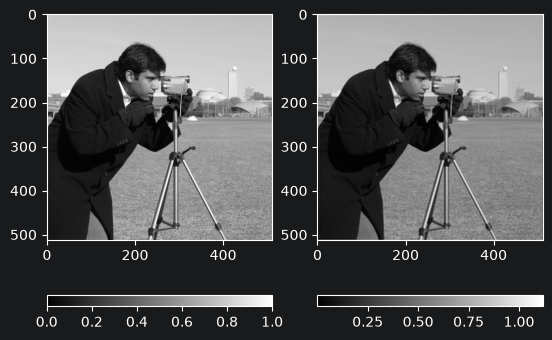

In [3]:
im  = img_as_float(data.camera())
r  = 100
imw  =  np.zeros_like(im)
cx, cy   = np.round(np.array(im.shape)/2)
rr, cc   = disk((cx, cy), r, shape=im.shape)
imw[rr, cc]    =  1
imfft   = fftshift(fft2(im))
imm  =  np.log(np.abs(imfft))
imfft[imw==0]     = 0
imf  =  np.abs(ifft2(imfft))
fig  =  plt.figure()
ax  = fig.add_subplot(1,      2,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      2,  2)
p  = plt.imshow(imf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## 4 Gaussian Low Pass Filter


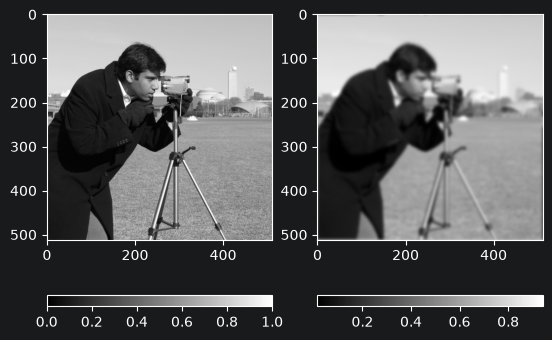

In [4]:
im  = img_as_float(data.camera())
xs, ys   = np.array(im.shape)
xl  = np.arange(xs)
yl  = np.arange(ys)
x, y  =  np.meshgrid(xl, yl, indexing='ij')
x  = (x-xs//2)/xs
y  = (y-ys//2)/ys
s  = 0.05
imw  =  np.exp(-(x**2+y**2)/(2*s**2))
# imw = np.exp(-((x/s)**2+(y/s)**2))
imfft   = fftshift(fft2(im))
imfft   = imfft   * imw
imf  =  np.abs(ifft2(imfft))
imm  =  np.log(np.abs(imfft))
imm  =  imm  * imw
fig  =  plt.figure()
ax  = fig.add_subplot(1,      2,  1)
p =  plt.imshow(im, cmap='gray')
c =  plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      2,  2)
p =  plt.imshow(imf, cmap='gray')
c =  plt.colorbar(orientation='horizontal')


## 5 Butterworth Low Pass Filter


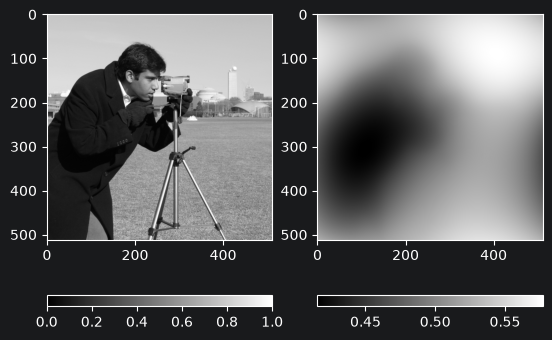

In [8]:
im  = img_as_float(data.camera())
xs, ys   = np.array(im.shape)
xl  = np.arange(xs)
yl  = np.arange(ys)
x, y  =  np.meshgrid(xl, yl, indexing='ij')
x =  (x-xs//2)/xs
y =  (y-ys//2)/ys
n =  1
K =  0.001
imw = 1 / (1 + np.sqrt(x**2+y**2)**(2*n) / K**(2*n))
imfft  =  fftshift(fft2(im))
imfft  =  imfft  *  imw
imf  = np.abs(ifft2(imfft))
imm  = np.log(np.abs(imfft))
imm  =  imm  * imw
fig  =  plt.figure()
ax  = fig.add_subplot(1,      2,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      2,  2)
p  = plt.imshow(imf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## 6 Correlation


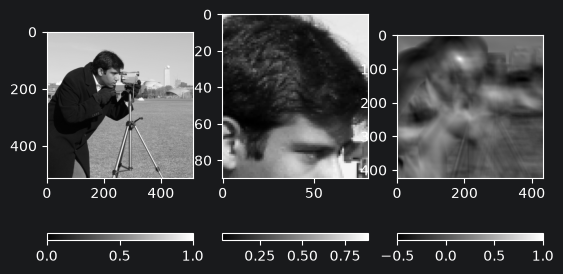

In [7]:
im  = img_as_float(data.camera())
imtemp   = im[70:160,186:266]
imm  =  match_template(im, imtemp)
fig  =  plt.figure()
ax  = fig.add_subplot(1,      3,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      3,  2)
p  = plt.imshow(imtemp, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      3,  3)
p  = plt.imshow(imm, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


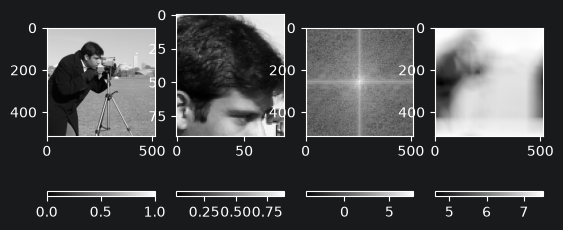

In [6]:
im  = img_as_float(data.camera())
imtemp   = im[70:160,186:266]
imm  =  np.log(np.abs(ifft2(fft2(im) * np.conj(fft2(imtemp,im.shape)))))
imtempf   =  np.log(np.abs(fftshift(fft2(imtemp,im.shape))))
fig  =  plt.figure()
ax  = fig.add_subplot(1,      4,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      4,  2)
p  = plt.imshow(imtemp, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      4,  3)
p  = plt.imshow(imtempf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      4,  4)
p  = plt.imshow(imm, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## 7 Deconvolution


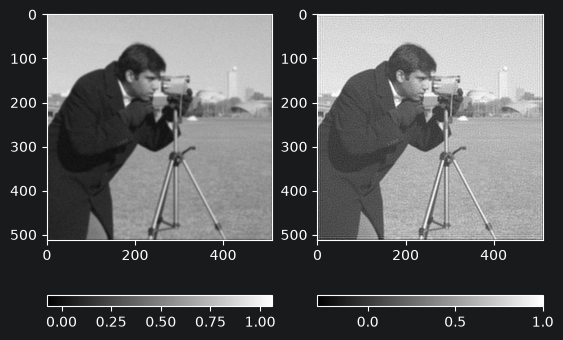

In [5]:
im  = img_as_float(data.camera())
kernel   = np.ones((5,5))     / 25
im  = convolve2d(im, kernel,       'same')
im  +=  0.1 *  im.std()   *  np.random.standard_normal(im.shape)
imf, _   = restoration.unsupervised_wiener(im, kernel)
fig  =  plt.figure()
ax  = fig.add_subplot(1,      2,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      2,  2)
p  = plt.imshow(imf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
